In [13]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv
import os

In [14]:
load_dotenv()

api_key = os.getenv("GEMINI_API_KEY")

In [15]:
llm = ChatGoogleGenerativeAI(
    model = "gemini-3.5-flash-lite",
    api_key = api_key
)

In [16]:
class Movie_Desc(TypedDict):
    movie : str
    related_movies : str
    realted_movies_description : str



In [25]:
def get_realted_movie(state: Movie_Desc) -> Movie_Desc:
    movie = state['movie']
    ques = f"Gimme 5 movies related to '{movie}' movie in a simple list like 'one','two',...."
    ans = llm.invoke(ques)

    state['related_movies'] = ans.text

    return state

In [26]:
def get_realted_movie_description(state: Movie_Desc) -> Movie_Desc:
    movie = state['movie']
    related_movies = state['related_movies']
    ques = f"Gimme a 10 words description on {related_movies} in format of {{'first movie name' : 'its 10 word decription' , 'second movie'........ likewise}}"
    ans = llm.invoke(ques)
    state['realted_movies_description'] = ans.text

    return state

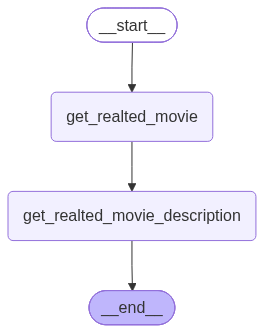

In [27]:
graph = StateGraph(Movie_Desc)

graph.add_node("get_realted_movie", get_realted_movie)
graph.add_node("get_realted_movie_description", get_realted_movie_description)

graph.add_edge(START, "get_realted_movie")
graph.add_edge("get_realted_movie", "get_realted_movie_description")
graph.add_edge("get_realted_movie_description", END)

workflow = graph.compile()
workflow

In [29]:
initial_state = {"movie" : "Batman"}
final_stage = workflow.invoke(initial_state)

print(final_stage['movie'])
print(final_stage['related_movies'])
print(final_stage['realted_movies_description'])

Batman
one, The Dark Knight
two, Batman Begins
three, The Dark Knight Rises
four, The Batman
five, Batman (1989)
```json
{
  "The Dark Knight": "Chaos reigns as Batman faces Gotham's ultimate psychological terrorist mastermind.",
  "Batman Begins": "Young Bruce Wayne travels the world, finding fear-fighting training.",
  "The Dark Knight Rises": "Broken hero returns from exile to save doomed Gotham city.",
  "The Batman": "Vengeful detective unravels corruption while hunting a serial killer.",
  "Batman (1989)": "Gothic vigilante terrorizes mobsters before battling the grinning Joker."
}
```
